# 1. prepare

In [ ]:
# mendownload untuk keperluan membaca, menulis, dan memodifikasi file xl
!pip install openpyxl

In [ ]:
# Import library yang diperlukan
import re
import nltk
import os
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer
from gensim.models.doc2vec import TaggedDocument, Doc2Vec
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

In [ ]:
# download NLTK stopwords dan WordNet
nltk.download('stopwords') # untuk keperluan efisiensi  analisis teks (kata-kata umum yang sering di abaikann)
nltk.download('punkt')# untuk memecahkann teks menjadi kata-kata atau kalimat
nltk.download('wordnet') # untuk mengelompokkan kata-kata kedalam set sinonim dan memberikan hubungan semantik diantara mereka
nltk.download('punkt_tab')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


True

In [ ]:
# menghubungkan notebook colab ke google drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# menghubungkan colab agar pencarian file tertuju ke dalam my drive
path = '/content/drive/MyDrive/'
os.chdir(path)

In [ ]:
# membaca file yang ada di drive dengan format csv serta melakukan inisialisasi data yang telah di import
oi = pd.read_csv("gojek_doc2v.csv")

In [ ]:
# mengekstrak kolom dari dataframe dan mengonversinya menjadi (list)python
doc = oi['content'].tolist()
# mengonversi skor menjadi label sentimen (1 = positif, 0 = negatif)
labels = [1 if score >= 4 else 0 for score in oi['score']]
print("data label",labels)

data label [0, 0, 1, 0, 1, 1, 0, 1, 0, 0, 0, 0, 1, 1, 0, 0, 1, 1, 1, 0, 0, 0, 0, 0, 1, 1, 1, 1, 0, 0, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 0, 1, 0, 0, 1, 0, 0, 1, 1, 1, 1, 1, 0, 0, 1, 1, 0, 1, 1, 0, 0, 1, 1, 1, 0, 0, 1, 1, 1, 1, 1, 0, 0, 1, 0, 1, 1, 0, 0, 1, 1, 1, 1, 1, 1, 1, 0, 1, 0, 1, 1, 0, 1, 0, 1, 0, 1, 1, 1, 1, 1, 0, 1, 1, 0, 0, 1, 0, 1, 1, 0, 1, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 1, 1, 1, 1, 1, 0, 1, 1, 0, 0, 0, 1, 0, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 0, 1, 0, 0, 0, 1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 0, 1, 1, 0, 1, 0, 1, 1, 0, 1, 1, 1, 1, 0, 0, 1, 1, 1, 1, 1, 0, 1, 1, 1, 0, 0, 1, 1, 1, 0, 0, 0, 1, 0, 1, 1, 0, 1, 0, 1, 0, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 0, 0, 0, 1, 1, 0, 0, 0, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 1, 1, 1, 0, 1, 1, 0, 0, 1, 1, 0, 1, 1, 1, 0, 1, 0, 0, 1, 1, 1, 0, 1, 1, 1, 0, 1, 0, 0, 1, 1, 1, 1, 0, 1, 1, 0, 0, 1, 1, 1, 1, 0, 0, 0, 0, 1, 1, 0, 0, 1, 0, 1, 0, 1, 1, 1, 1, 1, 1, 0, 1, 0, 0, 1, 0, 1, 1, 0, 0, 1, 0, 1, 1, 1, 1, 0, 1, 0, 0, 1, 1, 0, 1, 0

# **2.processing**

In [ ]:
def preprocess_text(text):
    # memeriksa apakah variable text bertipe string
    if not isinstance(text, str):
        # diatas di abaiin kalau daftar kosong
        # gunnaiin ini "return []"
        # untuk mennghentikan pemrosesan dan mengembalikan daftar kosong kalo nilai bukan string
        # mengkonversi nilai non string menjadi string
        text = str(text)

    # ubah menjadi huruf kecil
    text = text.lower() # mengubah semua karakter string menjadi huruf kecil

    # hapus angka dan karakter khusus
    text = re.sub(r'\d+', '', text)
    text = re.sub(r'[^\w\s]', '', text)

    # tokenisasi
    words = word_tokenize(text) # memisahkan teks menjadi unit yang lebih kecil contohnya "dudu beli beras" menjadi "dudu" "beli" "beras"

    # hapus stopwords
    stop_words = set(stopwords.words('english'))
    words = [word for word in words if word not in stop_words] # menghapus kata2 stopwords ( kata yang kurang arti) contoh "apple is green" menjadi "apple" "green"

    # lemmatization
    lemmatizer = WordNetLemmatizer()
    words = [lemmatizer.lemmatize(word) for word in words] # mengubah berbagai verb atau sinonim menjadi kata yang lebih simple contohnya running menjadi run doang, dan better menjadi good aja

    return words
processed_documents = [preprocess_text(d) for d in doc] # menerapkan preprocessing ke semua dokumen

In [ ]:
oi.isnull().sum()

,0
userName,0
content,1
score,0
at,0
appVersion,0


In [ ]:
oi.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2146 entries, 0 to 2145
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   userName    2146 non-null   object
 1   content     2145 non-null   object
 2   score       2146 non-null   int64 
 3   at          2146 non-null   object
 4   appVersion  2146 non-null   object
dtypes: int64(1), object(4)
memory usage: 84.0+ KB


# 3. konversi ke format taggeddokcument

In [ ]:
# mengubah semua data kedalam format taggeddocument dengan kaitan label/tag
tagged_data = [TaggedDocument(words=doc, tags=[str(i)]) for i, doc in enumerate(processed_documents)]
print(tagged_data)

[TaggedDocument(words=['akun', 'gopay', 'saya', 'di', 'blok'], tags=['0']), TaggedDocument(words=['lambat', 'sekali', 'sekarang', 'ini', 'bosssku', 'apk', 'gojek', 'gk', 'kaya', 'dulu'], tags=['1']), TaggedDocument(words=['kenapa', 'sih', 'dari', 'kemarin', 'sy', 'buka', 'aplikasi', 'gojek', 'malah', 'keluar', 'sendiri', 'terus', 'saya', 'kasih', 'bintang', 'dulu', 'kalo', 'sudah', 'normal', 'sy', 'kasih', 'bintang'], tags=['2']), TaggedDocument(words=['baru', 'download', 'gojek', 'dan', 'hape', 'baru', 'trus', 'ditop', 'u', 'gopay', 'transaksi', 'dialfamart', 'transaksi', 'bloked', 'transaksilaporan', 'di', 'pusat', 'bantuan', 'gak', 'jelas', 'yang', 'ditanyakan', 'apa', 'jawaban', 'lainlama', 'lama', 'gojek', 'dikelola', 'tokopedia', 'udah', 'nyimpangapa', 'gojek', 'anak', 'bangsa', 'seperti', 'dulu', 'apa', 'punya', 'tokopedia'], tags=['3']), TaggedDocument(words=['mantap'], tags=['4']), TaggedDocument(words=['bagus'], tags=['5']), TaggedDocument(words=['coba', 'dulu'], tags=['6']),

# 4. membangun dan melatih model doc2vec

In [ ]:
# inisialisasi model dengan parameter yang diperlukan
model = Doc2Vec(vector_size=50, window=2, min_count=2, workers=4, epochs=40)

# membangun kosakata
model.build_vocab(tagged_data)

# melatih model
model.train(tagged_data, total_examples=model.corpus_count, epochs=model.epochs)

# 5. menyimpan model

In [ ]:
model.save("doc2vec_model.model")
print("Model doc2vec selesai dilatih dan disimpan.")

Model doc2vec selesai dilatih dan disimpan.


In [ ]:
# memuat model yang telah disimpan
model = Doc2Vec.load("doc2vec_model.model")

# melihat jumlah dokumen yang disimpan
print(f"Jumlah dokumen yang telah disimpan: {len(model.dv)}")

Jumlah dokumen yang telah disimpan: 2146


In [ ]:
# melakukan extract vektor untuk setiap dokumen untuk digunakan sebagai fitur
doc_vectors = [model.dv[i] for i in range(len(processed_documents))]
print(doc_vectors)

[array([ 0.01646255,  0.03390843, -0.06100514, -0.04837419,  0.03469821,
       -0.1184677 , -0.00701495,  0.1452262 , -0.1276852 , -0.04740876,
       -0.01757304, -0.09859624,  0.02811082,  0.04428219, -0.06495614,
       -0.06810458,  0.21161936, -0.03866819, -0.15456352, -0.10730614,
        0.0203323 ,  0.11611357,  0.10618832, -0.03888237,  0.14557436,
        0.06757738, -0.0134551 , -0.03620843, -0.12190557, -0.01350042,
        0.08320562,  0.07906456, -0.04467753,  0.0551638 , -0.07705688,
        0.07804436, -0.04925732,  0.068855  ,  0.10860883, -0.12172056,
        0.07962523, -0.02314979,  0.01989601,  0.01856591,  0.16841178,
       -0.03712967,  0.03735396, -0.0713467 ,  0.15328959, -0.02287821],
      dtype=float32), array([-0.05338884, -0.02199748,  0.0997983 ,  0.02865645, -0.05176852,
       -0.01359886,  0.07829194,  0.08583892, -0.20060506, -0.01276316,
       -0.02005144, -0.03687692,  0.05698401,  0.06626126, -0.05282971,
        0.02956735,  0.11967605, -0.0283

# 6. untuk segmentasi test (hanya di ambil sebanyak 20% dari data keseluruhan)

In [ ]:
# prepare untuk memecah train_test
X_train, X_test, y_train, y_test = train_test_split(doc_vectors, labels, test_size=0.2, random_state=42)
print("Jumlah data latih:", len(X_train))
print("Jumlah data uji:", len(X_test))

Jumlah data latih: 1716
Jumlah data uji: 430


In [ ]:
# melakukann pengklasifikasian Train  (regressi logistic)
classifier = LogisticRegression()
classifier.fit(X_train, y_train)

LogisticRegression()

logisticregression() artinya objek model berhasil untuk dilatih

In [ ]:
# melakukan prediksi sentiment untuk menguji data
y_pred = classifier.predict(X_test)
print(y_pred)

[1 1 1 1 1 1 0 1 1 0 1 1 0 0 1 0 1 1 1 0 0 0 1 1 1 1 0 0 1 1 0 1 1 1 1 0 1
 0 1 1 0 1 1 1 1 1 0 1 1 1 1 1 0 1 1 1 1 1 1 1 1 0 1 1 1 1 0 0 1 1 1 1 0 1
 1 1 1 1 0 1 0 0 1 1 1 0 1 0 0 0 0 0 1 1 1 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 0 1 1 1 1 1 0 1 1 1 1 0 0 0 1 1 0 1 0 1 1 1 0 1 1 0 1 0 1 1 1 1 1 1 1 1 1
 0 1 1 1 1 1 0 1 0 1 1 1 1 0 1 0 1 1 1 1 1 1 0 1 1 1 1 1 0 0 1 1 1 1 1 1 1
 0 0 0 1 1 1 0 1 1 0 1 1 1 0 1 1 0 1 1 1 1 1 1 1 0 1 0 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 0 1 1 1 0 0 1 1 1 0 0 1 0 1 0 1 1 0 1 0 0 1 1 1 1 1 1 0 0 1 0 1
 1 1 1 1 1 1 1 1 1 1 1 0 1 1 1 1 1 1 0 0 1 1 0 1 1 1 1 1 0 1 1 1 1 0 0 1 0
 1 1 1 1 0 1 1 1 1 1 1 0 1 1 1 1 1 1 1 1 1 0 1 1 0 1 1 1 1 1 0 1 0 0 1 0 1
 0 0 1 0 1 0 1 1 1 1 0 0 1 1 1 1 1 1 1 1 1 0 0 1 1 1 1 1 0 1 0 0 0 1 1 1 1
 1 1 1 1 1 1 1 1 0 1 1 1 1 0 0 1 1 1 1 0 1 0 0 1 1 1 1 1 1 1 1 1 1 0 1 1 1
 0 1 1 1 1 1 0 1 0 1 1 1 1 1 1 1 1 0 1 1 1 1 0]


<ipython-input-20-db7db57352b0>:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=y_pred, palette='coolwarm')


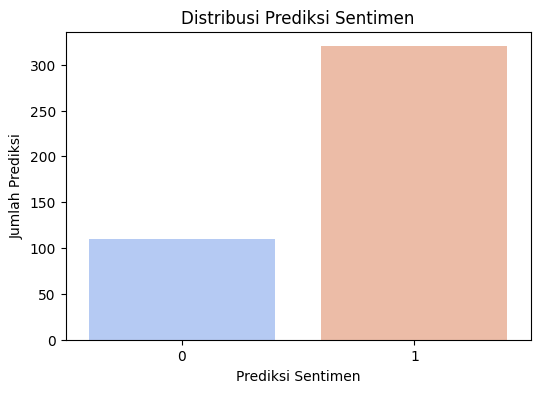

In [ ]:
# menampilkan distribusi prediksi
plt.figure(figsize=(6, 4))
sns.countplot(x=y_pred, palette='coolwarm')
plt.title('Distribusi Prediksi Sentimen')
plt.xlabel('Prediksi Sentimen')
plt.ylabel('Jumlah Prediksi')
plt.show()

In [ ]:
# melakukan evaluasi model
accuracy = accuracy_score(y_test, y_pred) #menghitung akurasi prediksi dibandingkan dengan label aktual
print("Akurasi klasifikasi sentimen:", accuracy)
print("Laporan klasifikasi:")
print(classification_report(y_test, y_pred)) #menyediakan kebutuhan metrik evaluasi/ head judul seperti precision, recall, f1-score, accuracy

Akurasi klasifikasi sentimen: 0.8
Laporan klasifikasi:
              precision    recall  f1-score   support

           0       0.81      0.58      0.67       154
           1       0.80      0.92      0.86       276

    accuracy                           0.80       430
   macro avg       0.80      0.75      0.76       430
weighted avg       0.80      0.80      0.79       430



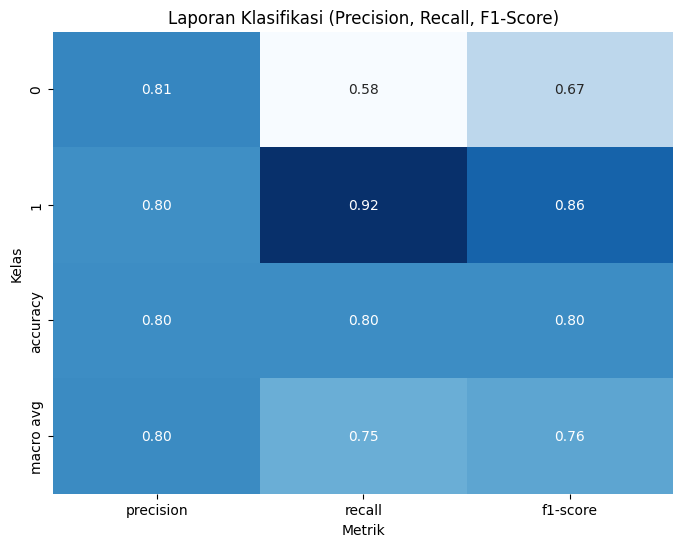

In [ ]:
# visualisasi Laporan Klasifikasi dalam bentuk Heatmap
# mendapatkan laporan klasifikasi sebagai dictionary
report = classification_report(y_test, y_pred, output_dict=True)

# mengonversi laporan klasifikasi ke dalam DataFrame
report_df = pd.DataFrame(report).transpose()

# plot heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(report_df.iloc[:-1, :-1], annot=True, cmap='Blues', fmt='.2f', cbar=False) #mengevaluasi perfoema model dalam klasifikasi sentimen
plt.title('Laporan Klasifikasi (Precision, Recall, F1-Score)')
plt.xlabel('Metrik')
plt.ylabel('Kelas')
plt.show()

1. Akurasi Klasifikasi:
* 0.8023 (80.23%): Ini menunjukkan persentase total prediksi yang benar oleh model dibandingkan dengan jumlah total data. Dalam hal ini, model benar mengklasifikasikan sekitar 80.23% dari 430 data.

2. Laporan Klasifikasi:
Laporan ini memberikan metrik evaluasi yang lebih detail tentang seberapa baik model dalam mengklasifikasikan dua kelas (kelas 0 dan kelas 1). Ada empat metrik utama yang digunakan:

* Precision (Presisi): Mengukur seberapa banyak prediksi positif yang benar di antara semua prediksi positif yang dibuat oleh model.

* Recall (Recall): Mengukur seberapa banyak data yang benar-benar positif yang berhasil dikenali oleh model.

* F1-Score (F1-Score): Merupakan rata-rata harmonis antara precision dan recall. F1-score digunakan untuk mengukur keseimbangan antara precision dan recall, terutama ketika ada ketidakseimbangan antara kelas.

* Support: Menunjukkan jumlah data untuk setiap kelas.

3. Akurasi Total:
* Akurasi adalah 0.80, yang berarti 80% dari total prediksi model benar.

4. Rata-rata Makro dan Rata-rata Tertimbang:
* Macro Average (Rata-rata Makro): Menghitung rata-rata dari precision, recall, dan f1-score untuk kedua kelas, tanpa memperhatikan jumlah data di setiap kelas.
  * Precision makro adalah 0.81.
  * Recall makro adalah 0.75.
  * F1-score makro adalah 0.77.
Rata-rata makro menunjukkan keseimbangan keseluruhan antara kedua kelas tanpa mempertimbangkan distribusi data.

* Weighted Average (Rata-rata Tertimbang): Menghitung rata-rata dari precision, recall, dan f1-score dengan memperhatikan proporsi data pada setiap kelas. Kelas dengan jumlah data lebih banyak akan memberikan kontribusi lebih besar terhadap rata-rata ini.
  * Precision tertimbang adalah 0.80.
  * Recall tertimbang adalah 0.80.
  * F1-score tertimbang adalah 0.79.
Rata-rata tertimbang menunjukkan seberapa baik model bekerja ketika distribusi kelas tidak seimbang.

In [ ]:
# melakukan prediksi sentiment untuk keperluan dokumen baru
new_document = ["example", "text", "to", "classify"]
new_vector = model.infer_vector(new_document)#mendapatkan vektor representasi dokumen baru
predicted_sentiment = classifier.predict([new_vector])[0] #melakukan prediksi sentimen dokumen baru
print("Sentimen prediksi untuk dokumen baru:", "Positif" if predicted_sentiment == 1 else "Negatif")

Sentimen prediksi untuk dokumen baru: Positif


# 7. Tahap Extract pemilahan data positif dan negatif Excell

In [ ]:
# Mengonversi skor menjadi label sentimen (1 = positif, 0 = negatif)
labels = [1 if score >= 4 else 0 for score in oi['score']]
oi['label'] = labels  # Menambahkan kolom label ke DataFrame

In [ ]:
# Melakukan save modul doc2vec
model.save("doc2vec_model.model")

In [ ]:
# Melakukan pengelompokan konten
positive_comments = oi[oi['label'] == 1]['content'].tolist()
negative_comments = oi[oi['label'] == 0]['content'].tolist()

In [ ]:
# Mempersiapkan kolom dalam excell
output_df = pd.DataFrame({
    'Content': positive_comments + negative_comments,
    'Sentiment': ['Positive'] * len(positive_comments) + ['Negative'] * len(negative_comments)
})

In [ ]:
#membuat penamaan file
output_path = "sentiment_analysis_results.xlsx"
output_df.to_excel(output_path, index=False)
print(f"Data telah disimpan ke dalam file {output_path}")

Data telah disimpan ke dalam file sentiment_analysis_results.xlsx


In [ ]:
# download/import data penyimpanan local
from google.colab import files
files.download(output_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>